# 03 - Especialização com LoRA
**Requisito 05.** Ajuste fino do `Qwen2.5-1.5B-Instruct` com LoRA para: (1) responder **sempre em JSON válido**, (2) **citar o id do trecho** usado e (3) **recusar** quando o contexto não responde. O conhecimento continua vindo da base (RAG). Os dados de treino são gerados dos trechos e **não incluem** os casos de teste.
Use GPU (Colab T4). Dura ~20-40 min.

In [1]:
# Setup (Colab: Ambiente de execução > Alterar tipo > GPU T4). Local: só rode a partir da raiz do repositório.
import os, sys, subprocess
REPO = "https://github.com/melo-zz/calcada-livre-genai.git"   # <- troque pelo link do repositório público da equipe
if os.path.exists("/content"):                                  # estamos no Colab
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO, "/content/repo"], check=True)
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("pasta de trabalho:", os.getcwd())

pasta de trabalho: /content/repo


In [2]:
%pip install -q -r requirements.txt
%pip uninstall -y -q torchao

In [3]:
import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass

In [4]:
import os
from src.kb import carregar_trechos
from src.retrieval import Retriever
from src.lora_data import construir, salvar
os.makedirs(".cache", exist_ok=True)
trechos = carregar_trechos("base/trechos.jsonl")
r = Retriever(trechos, cache=".cache/emb.npy")
exemplos = construir(trechos, retriever=r, n_consta=360, n_nc=120, seed=SEED)
salvar(exemplos)
print(len(exemplos), "exemplos de treino (360 'consta' + 120 'não consta')")
print(exemplos[0]["messages"][-1]["content"][:400]); print("ALVO:", exemplos[0]["alvo"])

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/40 [00:00<?, ?it/s]

480 exemplos de treino (360 'consta' + 120 'não consta')
Trechos:
[l10741_art55_p2] Lei 10.741/2003, § 2º A suspensão parcial ou total do repasse de verbas públicas ocorrerá quando verificada a má aplicação ou desvio de finalidade dos recursos.
§ 3º Na ocorrência de infração por entidade de atendimento que coloque em risco os direitos assegurados nesta Lei, será o fato comunicado ao Ministério Público, para as providências cabíveis, inclusive para promo
ALVO: {"resposta": "Art. 96. Discriminar pessoa idosa, impedindo ou dificultando seu acesso a operações bancárias, aos meios de transporte, ao direito de contratar ou por qualquer outro meio ou instrumento necessário ao exercício da cidadania, por motivo de idade: Pena – reclusão de 6 (seis) meses a 1 (um) ano e multa.", "fontes": ["l10741_art96"], "consta": true}


In [5]:
from src.treino_lora import treinar
log = treinar(exemplos, saida="modelo/lora_qwen15b", epocas=2, seed=SEED)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
480 exemplos de treino (0 descartados por tamanho)


Step,Training Loss
5,0.096176
10,0.038063
15,0.028384
20,0.016825
25,0.019302
30,0.014302
35,0.009996
40,0.007847
45,0.008666
50,0.007230


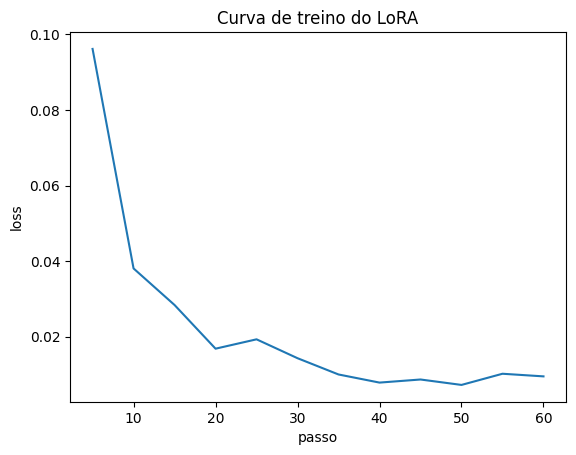

adaptador salvo em modelo/lora_qwen15b (não vai para o GitHub; reproduza com este notebook)


In [6]:
import matplotlib.pyplot as plt
loss = [(l["step"], l["loss"]) for l in log if "loss" in l]
plt.plot(*zip(*loss)); plt.xlabel("passo"); plt.ylabel("loss"); plt.title("Curva de treino do LoRA")
plt.savefig("avaliacao/loss_lora.png", dpi=150, bbox_inches="tight"); plt.show()
print("adaptador salvo em modelo/lora_qwen15b (não vai para o GitHub; reproduza com este notebook)")

Para usar o adaptador no notebook 04 em outra sessão do Colab, salve a pasta `modelo/lora_qwen15b` no Google Drive, ou rode o 03 e o 04 na mesma sessão.